In [1]:
import pandas as pd
import numpy as np

In [4]:
df=pd.read_csv(r"C:\Users\shahz\Desktop\Learnings\ann for regression\powerplant_data.csv")
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [5]:
#AT => temperature
#V => vacuum
#AP => pressure
# RH => humidity

#PE => produced energy


In [6]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [11]:
X= df.drop("PE", axis=1)
y=df["PE"]

In [12]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(7654, 4) (1914, 4)
(7654,) (1914,)


In [15]:
df.shape

(9568, 5)

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn mean and std from training data only, then transform it
X_train_scaled = scaler.fit_transform(X_train)

# Use the same mean and std to transform test data
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.mean(axis=0))
print(X_train_scaled.std(axis=0))

[-2.44614595e-16 -4.56273523e-16 -2.10452101e-15 -1.05829464e-16]
[1. 1. 1. 1.]


In [17]:
import torch

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

print(X_train_tensor.shape, y_train_tensor.shape)
print(X_test_tensor.shape, y_test_tensor.shape)

torch.Size([7654, 4]) torch.Size([7654, 1])
torch.Size([1914, 4]) torch.Size([1914, 1])


In [18]:
import torch.nn as nn

class PowerPlantANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(4, 6),   # input -> hidden 1
            nn.ReLU(),
            nn.Linear(6, 6),   # hidden 1 -> hidden 2
            nn.ReLU(),
            nn.Linear(6, 1)    # hidden 2 -> output
        )

    def forward(self, x):
        return self.model(x)

model = PowerPlantANN()
print(model)

PowerPlantANN(
  (model): Sequential(
    (0): Linear(in_features=4, out_features=6, bias=True)
    (1): ReLU()
    (2): Linear(in_features=6, out_features=6, bias=True)
    (3): ReLU()
    (4): Linear(in_features=6, out_features=1, bias=True)
  )
)


In [19]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Check one batch
for xb, yb in train_loader:
    print(xb.shape, yb.shape)
    break

print(len(train_loader))

torch.Size([32, 4]) torch.Size([32, 1])
240


In [21]:
import torch.optim as optim

class ANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 6),   # 1st hidden
            nn.ReLU(),
            nn.Linear(6, 6),           # 2nd hidden
            nn.ReLU(),
            nn.Linear(6, 1)            # output
        )

    def forward(self, x):
        return self.model(x)

model = ANN(X_train.shape[1])

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

print(model)
print(criterion)
print(optimizer)

ANN(
  (model): Sequential(
    (0): Linear(in_features=4, out_features=6, bias=True)
    (1): ReLU()
    (2): Linear(in_features=6, out_features=6, bias=True)
    (3): ReLU()
    (4): Linear(in_features=6, out_features=1, bias=True)
  )
)
MSELoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


In [24]:
# Train the ANN and save the best model (based on validation loss)

epochs = 100
train_losses = []
val_losses = []
best_val_loss = float("inf")
best_epoch = 0

for epoch in range(epochs):
    # ---------- Training ----------
    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:
        optimizer.zero_grad()              # clear old gradients
        outputs = model(xb)                # forward pass
        loss = criterion(outputs, yb)      # compute loss
        loss.backward()                    # backward pass (autograd)
        optimizer.step()                   # update weights and biases

        running_loss += loss.item()

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    # ---------- Validation ----------
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs, yb)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    # ---------- Save the best model ----------
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_model.pt")

    print(f"Epoch {epoch+1}/{epochs} ==> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

print(f"\nBest Val Loss: {best_val_loss:.4f} at epoch {best_epoch}")

Epoch 1/100 ==> Train Loss: 23.4351 | Val Loss: 30.6137
Epoch 2/100 ==> Train Loss: 23.8604 | Val Loss: 22.0995
Epoch 3/100 ==> Train Loss: 22.9959 | Val Loss: 19.4555
Epoch 4/100 ==> Train Loss: 24.0504 | Val Loss: 20.2204
Epoch 5/100 ==> Train Loss: 23.5182 | Val Loss: 20.2383
Epoch 6/100 ==> Train Loss: 22.8974 | Val Loss: 23.7284
Epoch 7/100 ==> Train Loss: 23.0484 | Val Loss: 21.7676
Epoch 8/100 ==> Train Loss: 23.0247 | Val Loss: 28.8539
Epoch 9/100 ==> Train Loss: 23.6156 | Val Loss: 19.8608
Epoch 10/100 ==> Train Loss: 22.7503 | Val Loss: 20.8867
Epoch 11/100 ==> Train Loss: 23.2650 | Val Loss: 20.4274
Epoch 12/100 ==> Train Loss: 22.8615 | Val Loss: 20.4757
Epoch 13/100 ==> Train Loss: 23.0871 | Val Loss: 21.1571
Epoch 14/100 ==> Train Loss: 23.8025 | Val Loss: 20.8794
Epoch 15/100 ==> Train Loss: 23.6017 | Val Loss: 19.9411
Epoch 16/100 ==> Train Loss: 23.3221 | Val Loss: 20.2832
Epoch 17/100 ==> Train Loss: 23.6028 | Val Loss: 23.2341
Epoch 18/100 ==> Train Loss: 23.9558 | V

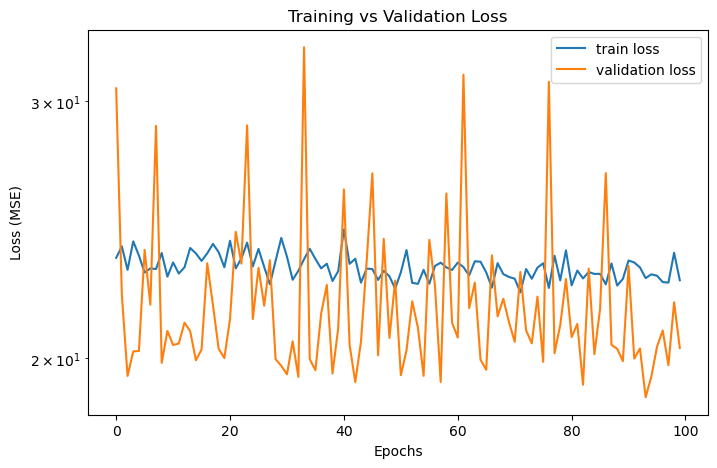

In [25]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "train loss": train_losses,
    "validation loss": val_losses
})

plt.figure(figsize=(8, 5))
plt.plot(loss_df["train loss"], label="train loss")
plt.plot(loss_df["validation loss"], label="validation loss")
plt.yscale("log")   # log scale because the first epochs have a very large loss
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [26]:
# Load the weights of the best epoch into the model
model.load_state_dict(torch.load("best_model.pt", weights_only=True))
model.eval()

ANN(
  (model): Sequential(
    (0): Linear(in_features=4, out_features=6, bias=True)
    (1): ReLU()
    (2): Linear(in_features=6, out_features=6, bias=True)
    (3): ReLU()
    (4): Linear(in_features=6, out_features=1, bias=True)
  )
)

In [27]:
from sklearn.metrics import r2_score

with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse = criterion(train_preds, y_train_tensor)
    test_mse = criterion(test_preds, y_test_tensor)

print(f"Training MSE: {train_mse.item():.4f}")
print(f"Testing MSE : {test_mse.item():.4f}")
print(f"Test RMSE   : {test_mse.item() ** 0.5:.4f} MW")
print(f"Test R2     : {r2_score(y_test_tensor.numpy(), test_preds.numpy()):.4f}")

Training MSE: 20.5502
Testing MSE : 18.8185
Test RMSE   : 4.3380 MW
Test R2     : 0.9342


In [28]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

compare_df = pd.concat([predicted_df, actual_df], axis=1)
compare_df["Difference"] = compare_df["Actual Values"] - compare_df["Predicted Values"]
compare_df.head(10)

,Predicted Values,Actual Values,Difference
0,435.650330,433.27,-2.380330
1,436.583527,438.16,1.576473
2,461.417236,458.42,-2.997236
3,475.935974,480.82,4.884026
4,435.467682,441.41,5.942318
5,459.247253,454.75,-4.497253
6,480.833862,483.26,2.426138
7,478.282898,478.25,-0.032898
8,439.157227,434.16,-4.997227
9,469.719055,470.66,0.940945
